# RQ2 — fine-tuning curve on NISAR chips (issue #24)

How many labelled NISAR chips does it take to recover what the Sentinel-1 model
loses on L-band? This notebook fine-tunes a Sen1Floods11 source model on
n = 0, 5, 10, 20, 35 NISAR chips across 3 seeds and plots the curve with error bars.

**Runtime:** roughly 25 minutes for the ResNet-50 arm on a T4; the MaxViT arm is
about four times that. The whole sweep fits in one Colab session.

### Design choices

**A fixed step budget, not epochs.** Every point trains for the same 300 optimiser
steps. Counting epochs instead would give n=35 seven times the updates of n=5, and
the curve would confound *more data* with *more training*.

**No checkpoint selection.** The 35-chip pool and the 20-chip test set are the only
labelled NISAR data that exists, so there is no third split to pick an epoch on.
Selecting the best epoch by test score would report a number tuned on the chips it
claims to generalise to. Each run is scored as it stands when the budget runs out.

The split is fixed in `data/labels/rq2_splits.json` and explained in
`docs/rq2_splits.md`. It is not re-drawn here: the RQ1 zero-shot run (#22)
is scored on the same 20 chips, which is what makes its number the n=0 point of
this curve.

## 1. Code

In [16]:
import os, shutil

REPO   = "https://github.com/cs59300-deep-learning/nisar-flood-mapping.git"
BRANCH = "feat/24-rq2-splits"   # "main" once the PR is merged

# Clone outside any previous clone, so re-running this cell replaces it
# instead of nesting a second copy inside the first.
BASE = next(d for d in ["/content", "/kaggle/working", os.getcwd()] if os.path.isdir(d))
os.chdir(BASE)
shutil.rmtree("nisar-flood-mapping", ignore_errors=True)
!git clone --quiet --branch $BRANCH --depth 1 $REPO
os.chdir("nisar-flood-mapping")
!git log --oneline -1

5319e8e (grafted, HEAD -> feat/24-rq2-splits, origin/feat/24-rq2-splits) feat(rq2): improve huggingface authentication flow in finetune notebook


The scaffold commit created every source file empty, and Python imports an empty
module without complaint. This cell fails loudly on the wrong branch rather than
silently producing no results five cells later.

In [17]:
import pathlib

for f in ["src/nisar_flood/experiments/finetune_curve.py",
          "src/nisar_flood/datasets/nisar_chips.py",
          "scripts/make_rq2_splits.py",
          "configs/finetune.yaml",
          "data/labels/rq2_splits.json"]:
    size = pathlib.Path(f).stat().st_size
    assert size > 0, f"{f} is empty - the clone is on a branch without the implementation"
    print(f"{size:>8,} bytes  {f}")

  11,449 bytes  src/nisar_flood/experiments/finetune_curve.py
   4,163 bytes  src/nisar_flood/datasets/nisar_chips.py
   5,665 bytes  scripts/make_rq2_splits.py
   1,775 bytes  configs/finetune.yaml
  15,573 bytes  data/labels/rq2_splits.json


## 2. Hardware

In [18]:
import torch

if torch.cuda.is_available():
    name = torch.cuda.get_device_name(0)
    vram = torch.cuda.get_device_properties(0).total_memory / 1e9
    print(f"{name} | {vram:.0f} GB | bfloat16: {torch.cuda.is_bf16_supported()}")
    if torch.cuda.get_device_capability(0)[0] >= 8:
        torch.set_float32_matmul_precision("high")   # TF32 matmuls on A100/L4/H100
        print("TF32 enabled")
else:
    print("No GPU. Runtime > Change runtime type > T4 GPU, then rerun from cell 1.")

Tesla T4 | 16 GB | bfloat16: True


## 3. Dependencies

Colab has torch already. `segmentation_models_pytorch` brings the U-Net decoder and
the timm encoders; `rasterio` reads the chips.

In [19]:
!pip install --quiet segmentation-models-pytorch rasterio huggingface_hub
print("installed")

installed


## 4. Sign in to Hugging Face

The chips, the label masks and the source checkpoints all live in the private
`nisar-flood-mapping` organisation, so this step is required. An unauthenticated request for a private
repository returns **404, not 403**, so skipping this step surfaces three cells
later as a misleading "repository not found".

The token goes in **Colab Secrets** (the key icon in the left sidebar) under the
name `HF_TOKEN`, with notebook access switched on. A read-scope token from
hf.co/settings/tokens is sufficient.

Secrets rather than the login widget, because the widget does not pause **Run
all**: execution carries straight past it and every later cell runs signed out.
This cell halts the notebook instead.

In [20]:
from huggingface_hub import login, whoami

try:
    from google.colab import userdata
    token = userdata.get('HF_TOKEN')
except Exception:
    import os
    token = os.environ.get('HF_TOKEN')   # outside Colab, or no secret set

if token:
    login(token=token, add_to_git_credential=False)
else:
    from huggingface_hub import notebook_login
    notebook_login()    # type the token, then run this cell again to check it took

# Fail here rather than as a 404 on the first private download.
user = whoami()
orgs = [o['name'] for o in user.get('orgs', [])]
print('signed in as', user['name'], '| orgs:', orgs or 'none')
assert 'nisar-flood-mapping' in orgs, (
    'This token cannot see the nisar-flood-mapping organisation. Use a token from an '
    'account that is a member of it, and if it is fine-grained give it read access to '
    'that org.')

signed in as varunchundru | orgs: ['nisar-flood-mapping']


## 5. Pick the arm

Both arms run through the same code; only the source config and checkpoint differ.
The notebook is run once per arm.

The MaxViT checkpoint comes from #20. Its repository should be confirmed complete
before its curve is reported: at the time of writing it holds the weights but
neither `eval.json` nor `summary.json`, both of which the ResNet-50 repository has.

In [21]:
ARM = "resnet50"           # "resnet50" or "maxvit"

ARMS = {
    "resnet50": {"hf": "nisar-flood-mapping/unet-resnet50-sen1floods11",
                 "config": "configs/unet_resnet50.yaml",
                 "run": "runs/unet_resnet50/seed0/best.pt"},
    "maxvit":   {"hf": "nisar-flood-mapping/unet-maxvit-sen1floods11",
                 "config": "configs/unet_maxvit.yaml",
                 "run": "runs/unet_maxvit/seed0/best.pt"},
}
arm = ARMS[ARM]
OUT = f"runs/rq2_finetune_{ARM}"
print(ARM, "->", arm["hf"])

resnet50 -> nisar-flood-mapping/unet-resnet50-sen1floods11


## 6. Data

55 chips and their label masks, about 115 MB. The chips are two-band GeoTIFFs
holding HH and HV gamma0 in dB; the masks are 1 water, 0 dry, 2 suspected flooded
vegetation, -1 unusable.

In [22]:
from huggingface_hub import snapshot_download
import shutil, pathlib

local = snapshot_download(repo_id="nisar-flood-mapping/nisar-flood-masks-amazon",
                          repo_type="dataset",
                          allow_patterns=["chips/*", "labels/masks/*"])

for src, dst in [("chips", "data/chips"), ("labels/masks", "data/labels/masks")]:
    pathlib.Path(dst).parent.mkdir(parents=True, exist_ok=True)
    shutil.rmtree(dst, ignore_errors=True)
    shutil.copytree(pathlib.Path(local) / src, dst)

chips = sorted(pathlib.Path("data/chips").glob("*.tif"))
masks = sorted(pathlib.Path("data/labels/masks").glob("*_label.tif"))
print(f"{len(chips)} chips, {len(masks)} masks")
assert len(chips) == len(masks) == 55, "expected 55 of each"

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 110 files:   0%|          | 0/110 [00:00<?, ?it/s]

55 chips, 55 masks


## 7. Source checkpoint

The model being adapted. 130 MB for ResNet-50, 492 MB for MaxViT.

In [23]:
from huggingface_hub import hf_hub_download
import shutil, pathlib

ckpt = hf_hub_download(repo_id=arm["hf"], filename="seed0/best.pt")
dest = pathlib.Path(arm["run"])
dest.parent.mkdir(parents=True, exist_ok=True)
shutil.copy(ckpt, dest)
print(f"{dest} ({dest.stat().st_size / 1e6:.0f} MB)")

runs/unet_resnet50/seed0/best.pt (130 MB)


## 8. Check the split

This reads the committed split rather than drawing a new one. Rebuilding it would
give a different test set, and every number already reported against it — including
the zero-shot run — would stop being comparable.

In [24]:
import json

split = json.load(open("data/labels/rq2_splits.json"))
wf = split["water_fraction"]
mean = lambda ids: sum(wf[c] for c in ids) / len(ids)

print(f"test {split['test_size']} chips (mean water {mean(split['test']):.3f})")
print(f"pool {split['pool_size']} chips (mean water {mean(split['pool']):.3f})")
for seed, subsets in split["subsets"].items():
    print("  seed", seed, " ".join(f"n={n}:{mean(ids):.3f}" for n, ids in subsets.items()))

# Stratification is the point: water fraction stays flat across every subset,
# against a per-chip range of 0.00 to 0.90.

test 20 chips (mean water 0.376)
pool 35 chips (mean water 0.365)
  seed 0 n=5:0.344 n=10:0.372 n=20:0.365 n=35:0.365
  seed 1 n=5:0.333 n=10:0.337 n=20:0.365 n=35:0.365
  seed 2 n=5:0.328 n=10:0.363 n=20:0.357 n=35:0.365


## 9. Run the sweep

13 runs: one un-adapted evaluation plus 4 sizes x 3 seeds.

`--source-config` and `--source-checkpoint` point the sweep at the arm selected in
section 5. Without them the sweep fine-tunes whatever `configs/finetune.yaml`
names, which is the ResNet-50 arm.

Batch 8 fits a T4 for ResNet-50, 4 for MaxViT. Raising `--workers` matters more than
batch size here, because the chips are small and the GPU spends its time waiting on
GeoTIFF reads.

**After an interrupted session**, running this cell again reuses the finished runs
and continues from where the sweep stopped. `--force` redoes all of them, and a
change to any setting that would alter a result invalidates the affected runs on
its own.

Adding `--sizes 0 5 --seeds 0 --steps 10` exercises the same path in under a
minute, as a check before the full run.

In [25]:
# Shell cells below substitute $NAME and friends from these Python variables.
BATCH      = 8 if ARM == "resnet50" else 4   # MaxViT at batch 8 does not fit a T4
NAME       = f"rq2_finetune_{ARM}"
SRC_CONFIG = arm["config"]
SRC_CKPT   = arm["run"]

!PYTHONPATH=src python -m nisar_flood.experiments.finetune_curve \
    --config configs/finetune.yaml \
    --name $NAME \
    --source-config $SRC_CONFIG \
    --source-checkpoint $SRC_CKPT \
    --batch-size $BATCH --workers 2 \
    --out $OUT

rq2_finetune_resnet50 | cuda | 300 steps | test 20 chips
  n=0   seed=0  iou_water_per_chip_mean 0.6326  pooled 0.7784  (0.02 min)
  n=5   seed=0  iou_water_per_chip_mean 0.6827  pooled 0.7990  (1.09 min)
  n=5   seed=1  iou_water_per_chip_mean 0.6949  pooled 0.7950  (1.12 min)
  n=5   seed=2  iou_water_per_chip_mean 0.6976  pooled 0.7979  (1.12 min)
  n=10  seed=0  iou_water_per_chip_mean 0.7131  pooled 0.8148  (1.23 min)
  n=10  seed=1  iou_water_per_chip_mean 0.7130  pooled 0.8167  (1.23 min)
  n=10  seed=2  iou_water_per_chip_mean 0.6820  pooled 0.7817  (1.24 min)
  n=20  seed=0  iou_water_per_chip_mean 0.7131  pooled 0.8167  (1.47 min)
  n=20  seed=1  iou_water_per_chip_mean 0.7233  pooled 0.8250  (1.47 min)
  n=20  seed=2  iou_water_per_chip_mean 0.6959  pooled 0.8079  (1.47 min)
  n=35  seed=0  iou_water_per_chip_mean 0.7237  pooled 0.8202  (1.54 min)
  n=35  seed=1  iou_water_per_chip_mean 0.7263  pooled 0.8217  (1.55 min)
  n=35  seed=2  iou_water_per_chip_mean 0.7399  pooled 

The sweep writes `curve.json`, `curve.png` and one `run_n{n}_seed{s}.json` per run,
each carrying its per-chip IoUs for the error analysis in #25.

## 10. Results

In [26]:
import json

curve = json.load(open(f"{OUT}/curve.json"))
summary, metric = curve["summary"], curve["metric"]
baseline = summary["0"]["mean"]

print(f"{metric}, {curve['steps']} steps, {len(curve['test_chips'])} test chips\n")
print(f"{'n':>4}  {'mean':>6}  {'std':>6}  {'vs n=0':>7}")
for n in sorted(summary, key=int):
    s = summary[n]
    print(f"{n:>4}  {s['mean']:.4f}  {s['std']:.4f}  {s['mean'] - baseline:+.4f}")

iou_water_per_chip_mean, 300 steps, 20 test chips

   n    mean     std   vs n=0
   0  0.6326  0.0000  +0.0000
   5  0.6918  0.0079  +0.0591
  10  0.7027  0.0179  +0.0700
  20  0.7108  0.0139  +0.0781
  35  0.7300  0.0087  +0.0973


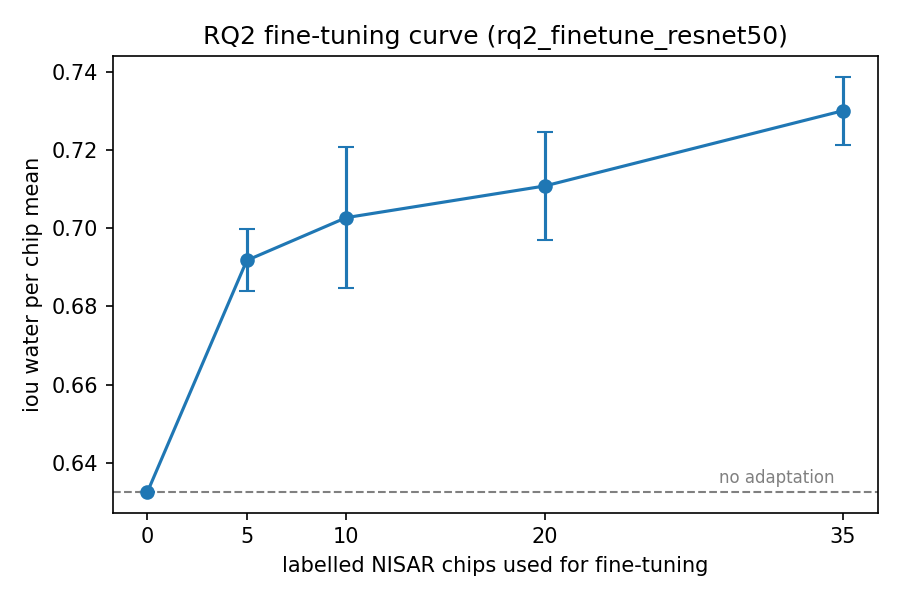

In [27]:
from IPython.display import Image, display

display(Image(f"{OUT}/curve.png"))

### Interpretation

- At **n=35 the pool is exhausted**, so all three seeds train on the same chips. The
  spread there is training randomness alone, not the draw, and its error bar is not
  comparable to the ones at n=5 and n=10.
- The **n=0 point is this curve's anchor, not the RQ1 result**. The reportable
  zero-shot figure is the one produced by #22, which also separates open water from
  flooded vegetation and compares against a dB threshold. That figure is the one to
  cite; this one exists to anchor the curve.
- **"N chips recover X% of the gap"** requires the gap, which is the source model's
  Sentinel-1 score minus its zero-shot NISAR score. It can be stated once #22 is
  reported.

## 11. Keep the results

Colab discards the filesystem when the session ends. The JSON and PNG are small
and are archived here so they survive the session.

In [28]:
import shutil

archive = shutil.make_archive(f"rq2_{ARM}", "zip", OUT)
print(archive, f"{pathlib.Path(archive).stat().st_size / 1e6:.1f} MB")

try:
    from google.colab import files
    files.download(archive)
except ImportError:
    print("Not on Colab - the archive is in the working directory.")

/content/nisar-flood-mapping/rq2_resnet50.zip 0.1 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Results enter the repository by unpacking the archive into
`reports/rq2_finetune_<arm>/` and committing `curve.json`, `curve.png` and the
per-run files. The `runs/` directory is
gitignored, which is why results are copied into `reports/` rather than committed
where they were written.